<a href="https://colab.research.google.com/github/HowardHNguyen/Data_Science_for_Healthcare/blob/main/Heart_Failure_Prediction_GenAI_400K_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart attack prediction on the BRFSS 2022 survey data: corrected, leak-free version

**Data:** `heart_attack_2022_400k.csv` (BRFSS 2022 telephone survey, 246,022 complete rows, 19 predictors, target `HeartAttack`).
This is a **cross-sectional self-report** survey: it estimates who *already* reports a heart attack. It is not a follow-up cohort.

This notebook keeps the structure of the original (base models, balancing, neural nets, stacking, GAN, tuning, validation) but
fixes the problems found in review. The full issue register is below; the unchanged original is saved next to this file as
`Heart-Failure-Prediction-GenAI-400K-dataset_ORIGINAL.ipynb`.

## Issues found in the original, and why they matter

| # | Severity | Original cells | Problem | Why it matters | Fix here |
|---|---|---|---|---|---|
| 1 | Critical | 27, 87, 92, 105, 108-111, 113, 121, 150 | SMOTE / ADASYN / SMOTETomek / GAN rows were created **before** the train/test split, so synthetic rows land in the test set | Test set is ~half synthetic; AUC jumps from ~0.84 to 0.95-0.98 without any real gain | All balancing happens **after** the split, on training rows only; test = real people at natural prevalence |
| 2 | Critical | 80, 85, 87, 105-121 | GAN trained on MinMax-scaled data; generated rows (values 0-1) were appended to the **raw-scale** table without `inverse_transform` | Synthetic BMI ≈ 0.4 vs real ≈ 28: a model detects "fake" by scale alone, which explains AUC 0.95-0.98 (and the 0.98 in the markdown of cell 89 does not even match the printed 0.947) | CTGAN works in original units; realism is checked (out-of-range %, detectability AUC) |
| 3 | Critical | 44, 53, 55, 58, 101, 105-121 | Stacking meta-learner fit on base-model predictions **of their own training rows** (in-sample) | Base models look near-perfect on training data, so the meta-learner over-trusts them; stack AUC fell to 0.66-0.68, *below* every base model | `StackingClassifier(cv=5)` builds meta-features out-of-fold |
| 4 | Critical | 29-33 | `X_train` left **unscaled** while `X_test` was scaled with a scaler fitted on the resampled set; LR/RF then trained on raw and tested on scaled | Train/test feature scales differ, so the 0.85 (LR) and 0.80 (RF) are meaningless | One pipeline per model; scaling fitted inside training |
| 5 | Critical | 25, 68, 99, 101, 122-128 | Notebook executed out of order: stale `HeartDisease` columns in memory, different test sizes (49,205 / 49,405 / 62,091 / 93,035), 11 vs 19 vs 17 features, several cells raise `NameError` | Results from different datasets/feature sets are compared as if equal; nothing is reproducible | Single linear flow; one data prep, one split, one feature list |
| 6 | High | 97, 105, 108, 131 | Decision thresholds (0.05...0.65) chosen by looking at **test** results | Test performance is optimistically biased | Threshold chosen on a separate validation split, applied once to test |
| 7 | High | 115, 118 | Hyper-parameter search on data containing synthetic duplicates; CNN search optimised `val_accuracy` on 5%-prevalence data (94% accuracy = predict "no"); `X_train_cnn` truncated and re-paired with a different `y_train` (labels misaligned) | Tuning picks models on leaked or meaningless criteria; misaligned labels | Tuning on real training rows with ROC-AUC |
| 8 | High | 80-87, 105-121 | Unconditional GAN fitted on both classes, then every synthetic row labelled 1; training collapsed (D loss ~1e-11, G loss ~25) and was used anyway; Tanh output on raw-scale data; cell 71 overwrites `scaler` with `GradScaler` | Synthetic "positives" are not positives; a collapsed generator emits noise | CTGAN fitted on **positives only**, training fold only, with quality diagnostics |
| 9 | High | 94 | `Angina` (a sibling coronary outcome) used as a predictor of `HeartAttack`: top importance (0.24) | Near-proxy for the label; inflates performance and is not a risk factor | Main analysis excludes it; an ablation shows its effect |
| 10 | High | 65, 99 | ROC for the MLP uses hard labels (`y_pred_nn`); `fpr, tpr` are overwritten so RNN and Stacking draw the same curve; legend duplicated | Plot and reported AUCs are wrong | One probability vector per model, one curve each |
| 11 | Medium | 105-131 | "CNN", "RNN", "GRU+attention" applied to unordered tabular columns; `SimpleCNN` is an MLP; "attention" is a softmax over raw inputs | No inductive benefit; names mislead | Kept for comparison but labelled honestly |
| 12 | Medium | 0, 15, 17 | Header says "400k, data from 2023"; the file has 246,022 rows (BRFSS 2022); ~4.5% rows are exact duplicates | Misreports the data; duplicates can sit on both sides of a random split | Documented; duplicates are kept **together** on one side of the split |
| 13 | Medium | 131 | "GenAI ONLY" uses a different dataset in memory (62,091-row test) and is an ordinary MLP | Not comparable; not generative AI | Removed / replaced by honest comparison |
| 14 | Medium | all | Only accuracy / ROC AUC to 2 dp, one split, no intervals, no calibration, no PR-AUC | At 5.5% prevalence accuracy and AUC hide poor precision; no uncertainty | AUC with bootstrap CI, PR-AUC, Brier, calibration slope, O/E |
| 15 | Low | 2, 20, 21, 63, 102, 103, 133, 134, 143, 148, 149 | Colab-only paths, empty/duplicate/"backup not run" cells, deprecated args (`use_label_encoder`, `shade=True`, `torch.cuda.amp`), `lat_dim` typo (cell 150), chunked SMOTE in 100k blocks | Clutter and fragility | Cleaned, portable paths |

## 0. Setup

In [1]:
import os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.environ.setdefault("OMP_NUM_THREADS", "1")   # avoids a torch / xgboost thread clash on some machines

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC, RandomOverSampler

QUICK = os.environ.get("NB_QUICK") == "1"          # smoke-test mode (small sample, few epochs)
SEED = 42
MAX_ROWS = 40_000 if QUICK else 0                  # 0 = every row
NN_EPOCHS = 2 if QUICK else 8
CTGAN_EPOCHS = 10 if QUICK else 100
CTGAN_ROWS = 1_000 if QUICK else 3_000             # CTGAN is fitted on at most this many positives
BOOT = 50 if QUICK else 200
USE_ANGINA = False                                  # Angina is a sibling coronary outcome (see issue 9)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
CANDIDATES = [Path("heart_attack_2022_400k.csv"),
              Path("/content/drive/MyDrive/data/heart_attack_2022_400k.csv"),
              Path.home() / "Documents/Projects/Heart Disease Project/heart_attack_2022_400k.csv"]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
assert DATA_PATH is not None, "Put heart_attack_2022_400k.csv next to this notebook (or edit CANDIDATES)."
print("data:", DATA_PATH, "| quick mode:", QUICK)

Mounted at /content/drive
data: /content/drive/MyDrive/data/heart_attack_2022_400k.csv | quick mode: False


## 1. Load and describe the data

In [2]:
raw = pd.read_csv(DATA_PATH)
if MAX_ROWS and len(raw) > MAX_ROWS:
    raw = raw.sample(MAX_ROWS, random_state=SEED).reset_index(drop=True)
print(raw.shape, "| missing cells:", int(raw.isna().sum().sum()), "| exact duplicate rows:", int(raw.duplicated().sum()))
print("HeartAttack prevalence: %.2f%%" % (100 * (raw.HeartAttack == "Yes").mean()))
raw.head()

(246022, 20) | missing cells: 0 | exact duplicate rows: 11038
HeartAttack prevalence: 5.46%


,Sex,GeneralHealth,PhysicalActivities,SleepHours,HeartAttack,Angina,Stroke,Asthma,SkinCancer,COPD,DepressiveDisorder,KidneyDisease,Arthritis,Diabetes,DifficultyWalking,SmokerStatus,Race,AgeCategory,BMI,Alcohol
0,Female,Very good,Yes,9,No,No,No,No,No,No,No,No,Yes,No,No,Yes,White,65-69,27.99,No
1,Male,Very good,Yes,6,No,No,No,No,No,No,No,No,Yes,Yes,No,Yes,White,70-74,30.13,No
2,Male,Very good,No,8,No,No,No,No,No,No,No,No,Yes,No,Yes,Yes,White,75-79,31.66,Yes
3,Female,Fair,Yes,9,No,No,No,No,Yes,No,Yes,No,Yes,No,Yes,No,White,80 or older,31.32,No
4,Female,Good,Yes,5,No,No,No,No,No,No,No,No,Yes,No,No,No,White,80 or older,33.07,No


## 2. Encoding (one explicit, documented mapping)
Yes/No -> 1/0, `Sex` -> male=1, `GeneralHealth` and `AgeCategory` -> ordered integers, `Race` -> one-hot (it is nominal; the original
coded it 1-5 as if ordered). The assertion guards against the silent NaNs that an unmatched mapping key would create.

In [3]:
AGE = {'18-24': 1, '25-29': 2, '30-34': 3, '35-39': 4, '40-44': 5, '45-49': 6, '50-54': 7, '55-59': 8,
       '60-64': 9, '65-69': 10, '70-74': 11, '75-79': 12, '80 or older': 13}
GENH = {'Poor': 1, 'Fair': 2, 'Good': 3, 'Very good': 4, 'Excellent': 5}
YN = ['PhysicalActivities', 'Angina', 'Stroke', 'Asthma', 'SkinCancer', 'COPD', 'DepressiveDisorder',
      'KidneyDisease', 'Arthritis', 'Diabetes', 'DifficultyWalking', 'SmokerStatus', 'Alcohol']

df = pd.DataFrame(index=raw.index)
df['HeartAttack'] = (raw.HeartAttack == 'Yes').astype(int)
df['Sex'] = (raw.Sex == 'Male').astype(int)
df['GeneralHealth'] = raw.GeneralHealth.map(GENH)
df['AgeCategory'] = raw.AgeCategory.map(AGE)
df['SleepHours'] = raw.SleepHours
df['BMI'] = raw.BMI
for c in YN:
    df[c] = (raw[c] == 'Yes').astype(int)
df = pd.concat([df, pd.get_dummies(raw.Race, prefix='Race', dtype=int)], axis=1)
assert df.isna().sum().sum() == 0, "an unmapped category produced NaN"

target = 'HeartAttack'
RACE = [c for c in df.columns if c.startswith('Race_')]
BINARY = ['Sex'] + [c for c in YN if c != 'Angina'] + (['Angina'] if USE_ANGINA else []) + RACE
FEATURES = [c for c in df.columns if c != target and (USE_ANGINA or c != 'Angina')]
print(len(FEATURES), "features:", FEATURES)

22 features: ['Sex', 'GeneralHealth', 'AgeCategory', 'SleepHours', 'BMI', 'PhysicalActivities', 'Stroke', 'Asthma', 'SkinCancer', 'COPD', 'DepressiveDisorder', 'KidneyDisease', 'Arthritis', 'Diabetes', 'DifficultyWalking', 'SmokerStatus', 'Alcohol', 'Race_Black', 'Race_Hispanic', 'Race_Multiracial', 'Race_Other', 'Race_White']


## 3. Quick look (EDA)

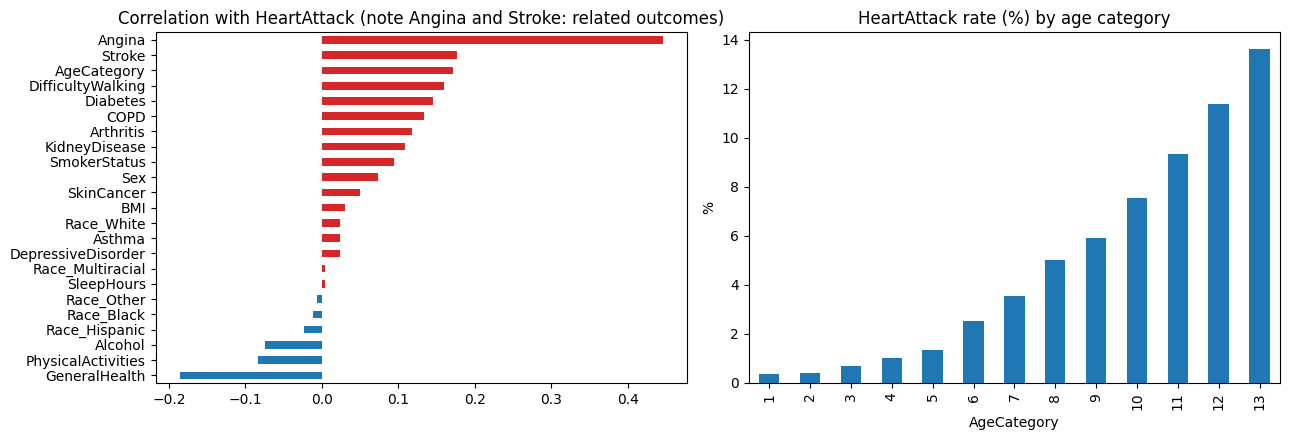

In [4]:
corr = df.corr()[target].drop(target).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
corr.plot.barh(ax=ax[0], color=np.where(corr > 0, "#d62728", "#1f77b4"))
ax[0].set_title("Correlation with HeartAttack (note Angina and Stroke: related outcomes)")
rate = df.groupby('AgeCategory')[target].mean() * 100
rate.plot.bar(ax=ax[1]); ax[1].set_title("HeartAttack rate (%) by age category"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

## 4. Train / validation / test split (done **once**, before anything is fitted)
Identical rows are kept together (grouped by a hash of the feature values) so a duplicate cannot sit in both train and test.
- **test (20%)**: real people, natural prevalence, touched once at the end of each experiment
- **validation (16%)**: early stopping, threshold choice
- **train_core (64%)**: everything is fitted here, including imputers, scalers, balancing and generators

In [5]:
ALLX = df[FEATURES + ([] if USE_ANGINA else ['Angina'])]          # Angina kept in the frame for the ablation only
y_all = df[target].to_numpy()
groups = pd.util.hash_pandas_object(df[FEATURES], index=False).to_numpy()

def first_fold(idx, k, seed):
    sgk = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
    tr, te = next(sgk.split(np.zeros(len(idx)), y_all[idx], groups[idx]))
    return idx[tr], idx[te]

all_idx = np.arange(len(df))
rest, test_idx = first_fold(all_idx, 5, SEED)
train_idx, val_idx = first_fold(rest, 5, SEED + 1)
assert not (set(groups[train_idx]) & set(groups[test_idx])), "duplicate rows leaked across the split"
for name, ix in [("train_core", train_idx), ("validation", val_idx), ("test", test_idx)]:
    print(f"{name:11s} n={len(ix):>7,}  prevalence={100*y_all[ix].mean():.2f}%")

Xtr, ytr = df.loc[train_idx, FEATURES].reset_index(drop=True), y_all[train_idx]
Xva, yva = df.loc[val_idx, FEATURES].reset_index(drop=True), y_all[val_idx]
Xte, yte = df.loc[test_idx, FEATURES].reset_index(drop=True), y_all[test_idx]

train_core  n=157,508  prevalence=5.48%
validation  n= 39,362  prevalence=5.39%
test        n= 49,152  prevalence=5.46%


## 5. Evaluation helpers (AUC with bootstrap CI, PR-AUC, Brier, calibration)

In [6]:
rng = np.random.default_rng(SEED)
BOOT_IDX = [rng.integers(0, len(yte), len(yte)) for _ in range(BOOT)]
RESULTS, PROBS = [], {}

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def calib(y, p):
    s = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), y).coef_[0, 0]
    return float(s), float(y.mean() / p.mean())

def record(experiment, name, p, base=None):
    PROBS[name] = p
    auc = roc_auc_score(yte, p)
    lo, hi = np.percentile([roc_auc_score(yte[b], p[b]) for b in BOOT_IDX], [2.5, 97.5])
    row = dict(experiment=experiment, model=name, AUC=auc, AUC_lo=lo, AUC_hi=hi,
               PR_AUC=average_precision_score(yte, p), Brier=float(np.mean((p - yte) ** 2)))
    row['calib_slope'], row['obs_over_exp'] = calib(yte, p)
    if base is not None and base in PROBS:
        d = [roc_auc_score(yte[b], p[b]) - roc_auc_score(yte[b], PROBS[base][b]) for b in BOOT_IDX]
        row['dAUC_vs_base'] = auc - roc_auc_score(yte, PROBS[base])
        row['dAUC_lo'], row['dAUC_hi'] = np.percentile(d, [2.5, 97.5])
    RESULTS.append(row)
    return row

def show(rows=None):
    t = pd.DataFrame(RESULTS if rows is None else rows).round(4)
    return t

def prior_shift(p, pi_real, pi_train):
    z = logit(p) + logit(np.array(pi_real)) - logit(np.array(pi_train))
    return 1 / (1 + np.exp(-z))
PI_REAL = float(ytr.mean())

## 6. Base models, no balancing
Logistic regression, random forest, gradient boosting (histogram GBM), XGBoost and an sklearn MLP, all on the **real**
training rows. Probabilities stay on the natural scale, so Brier and calibration are meaningful.

In [7]:
def base_models():
    return {
        'LR': make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)),
        'RF': RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features='sqrt', n_jobs=-1, random_state=SEED),
        'GBM': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=SEED),
        'XGB': XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8,
                             min_child_weight=3, tree_method='hist', n_jobs=1, eval_metric='logloss', random_state=SEED),
        'MLP': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                                             max_iter=60, random_state=SEED)),
    }

t0 = time.time()
FITTED = {}
for name, m in base_models().items():
    m.fit(Xtr, ytr); FITTED[name] = m
    record('1 no balancing', name, m.predict_proba(Xte)[:, 1])
    print(f"{name:4s} done ({time.time()-t0:.0f}s)")
show([r for r in RESULTS if r['experiment'] == '1 no balancing'])

LR   done (4s)
RF   done (37s)
GBM  done (44s)
XGB  done (52s)
MLP  done (66s)


,experiment,model,AUC,AUC_lo,AUC_hi,PR_AUC,Brier,calib_slope,obs_over_exp
0,1 no balancing,LR,0.8386,0.8328,0.8457,0.2437,0.0460,1.0215,0.9988
1,1 no balancing,RF,0.8387,0.8334,0.8456,0.2455,0.0458,1.1387,0.9965
2,1 no balancing,GBM,0.8408,0.8356,0.8477,0.2447,0.0457,1.0537,0.9970
3,1 no balancing,XGB,0.8413,0.8359,0.8482,0.2484,0.0457,1.0044,1.0020
4,1 no balancing,MLP,0.8361,0.8306,0.8423,0.2327,0.0461,0.9879,0.9986


## 7. Does balancing help? (applied to the **training rows only**)
Class weights, random oversampling and SMOTE-NC for LR and XGBoost. Balanced training inflates raw probabilities, so the
table also shows probabilities after a one-line prior-shift correction (this fixes calibration, not ranking).

In [8]:
cat_idx = [FEATURES.index(c) for c in BINARY if c in FEATURES]

def balanced_training_set(kind):
    if kind == 'ROS':
        Xa, ya = RandomOverSampler(random_state=SEED).fit_resample(Xtr, ytr)
    elif kind == 'SMOTE-NC':
        Xa, ya = SMOTENC(categorical_features=cat_idx, random_state=SEED, k_neighbors=5).fit_resample(Xtr, ytr)
    else:
        Xa, ya = Xtr, ytr
    return Xa, ya

rows = []
for kind in ['class weights', 'ROS', 'SMOTE-NC']:
    Xa, ya = balanced_training_set(kind)
    pi_train = 0.5 if kind != 'class weights' else 0.5
    for mname in ['LR', 'XGB']:
        if mname == 'LR':
            m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000,
                                                                 class_weight='balanced' if kind == 'class weights' else None))
        else:
            spw = float((ytr == 0).sum() / (ytr == 1).sum()) if kind == 'class weights' else 1.0
            m = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8,
                              min_child_weight=3, scale_pos_weight=spw, tree_method='hist', n_jobs=1,
                              eval_metric='logloss', random_state=SEED)
        m.fit(Xa, ya)
        p_raw = m.predict_proba(Xte)[:, 1]
        r = record('2 balancing', f'{mname} + {kind} (raw)', p_raw, base=mname)
        r2 = record('2 balancing', f'{mname} + {kind} (prior-corrected)', prior_shift(p_raw, PI_REAL, pi_train), base=mname)
        rows += [r, r2]
show(rows)

,experiment,model,AUC,AUC_lo,AUC_hi,PR_AUC,Brier,calib_slope,obs_over_exp,dAUC_vs_base,dAUC_lo,dAUC_hi
0,2 balancing,LR + class weights (raw),0.8387,0.8327,0.8459,0.2434,0.1703,0.9263,0.1551,0.0000,-0.0003,0.0004
1,2 balancing,LR + class weights (prior-corrected),0.8387,0.8327,0.8459,0.2434,0.0463,0.9260,0.9566,0.0000,-0.0003,0.0004
2,2 balancing,XGB + class weights (raw),0.8401,0.8342,0.8470,0.2475,0.1671,0.9899,0.1622,-0.0012,-0.0021,-0.0001
3,2 balancing,XGB + class weights (prior-corrected),0.8401,0.8342,0.8470,0.2475,0.0457,0.9904,1.0316,-0.0012,-0.0021,-0.0001
4,2 balancing,LR + ROS (raw),0.8386,0.8326,0.8458,0.2432,0.1704,0.9267,0.1551,-0.0001,-0.0004,0.0003
5,2 balancing,LR + ROS (prior-corrected),0.8386,0.8326,0.8458,0.2432,0.0463,0.9265,0.9568,-0.0001,-0.0004,0.0003
6,2 balancing,XGB + ROS (raw),0.8396,0.8330,0.8467,0.2445,0.1669,0.9879,0.1620,-0.0017,-0.0030,-0.0005
7,2 balancing,XGB + ROS (prior-corrected),0.8396,0.8330,0.8467,0.2445,0.0458,0.9884,1.0331,-0.0017,-0.0030,-0.0005
8,2 balancing,LR + SMOTE-NC (raw),0.8094,0.8027,0.8183,0.2011,0.1633,0.7483,0.1671,-0.0292,-0.0341,-0.0249
9,2 balancing,LR + SMOTE-NC (prior-corrected),0.8094,0.8027,0.8183,0.2011,0.0483,0.7482,0.9970,-0.0292,-0.0341,-0.0249


## 8. Neural networks (PyTorch): MLP, 1-D CNN, GRU
Trained on the real training rows with a class-weighted loss; early stopping uses the **validation** split; the output is
shifted back to the natural prevalence so probabilities stay interpretable. Convolution and recurrence treat the 22 columns as a
sequence, which they are not, so do not expect an advantage over the MLP.

In [9]:
import torch, torch.nn as nn
torch.set_num_threads(1)

class MLPNet(nn.Module):
    def __init__(self, d):
        super().__init__(); self.f = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x): return self.f(x)

class CNN1D(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.c = nn.Sequential(nn.Conv1d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2), nn.Flatten())
        self.h = nn.Sequential(nn.Linear(16 * (d // 2), 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x): return self.h(self.c(x.unsqueeze(1)))

class GRUNet(nn.Module):
    def __init__(self, d):
        super().__init__(); self.g = nn.GRU(1, 32, batch_first=True); self.o = nn.Linear(32, 1)
    def forward(self, x):
        _, h = self.g(x.unsqueeze(-1)); return self.o(h[-1])

def train_net(net, Xa, ya, Xv, yv, epochs, bs=1024, lr=2e-3):
    torch.manual_seed(SEED)
    pw = float((ya == 0).sum() / max(1, (ya == 1).sum()))
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pw]))
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    Xt, yt = torch.tensor(Xa, dtype=torch.float32), torch.tensor(ya, dtype=torch.float32).view(-1, 1)
    Xvt = torch.tensor(Xv, dtype=torch.float32)
    best_auc, best_state = -1, None
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), bs):
            ix = perm[i:i + bs]; opt.zero_grad(); crit(net(Xt[ix]), yt[ix]).backward(); opt.step()
        net.eval()
        with torch.no_grad(): pv = net(Xvt).numpy().ravel()
        a = roc_auc_score(yv, pv)
        if a > best_auc: best_auc, best_state = a, {k: v.clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state)
    return net, pw

def predict_net(net, X, pw):
    net.eval()
    with torch.no_grad(): z = net(torch.tensor(X, dtype=torch.float32)).numpy().ravel()
    return 1 / (1 + np.exp(-(z - np.log(pw))))          # undo the class-weight prevalence shift

sc = StandardScaler().fit(Xtr)
A, V, T = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
d = A.shape[1]
for label, cls in [('MLP (torch)', MLPNet), ('1-D CNN (torch)', CNN1D), ('GRU (torch)', GRUNet)]:
    t0 = time.time()
    net, pw = train_net(cls(d), A, ytr, V, yva, NN_EPOCHS)
    r = record('3 neural nets', label, predict_net(net, T, pw), base='LR')
    print(f"{label:16s} AUC={r['AUC']:.4f}  ({time.time()-t0:.0f}s)")
show([r for r in RESULTS if r['experiment'] == '3 neural nets'])

MLP (torch)      AUC=0.8406  (20s)
1-D CNN (torch)  AUC=0.8403  (25s)
GRU (torch)      AUC=0.8164  (72s)


,experiment,model,AUC,AUC_lo,AUC_hi,PR_AUC,Brier,calib_slope,obs_over_exp,dAUC_vs_base,dAUC_lo,dAUC_hi
0,3 neural nets,MLP (torch),0.8406,0.8356,0.8474,0.2465,0.0459,0.9565,0.8869,0.0020,-0.0000,0.0035
1,3 neural nets,1-D CNN (torch),0.8403,0.8348,0.8471,0.2444,0.0459,1.0058,1.1571,0.0017,-0.0002,0.0033
2,3 neural nets,GRU (torch),0.8164,0.8106,0.8242,0.2128,0.0470,1.1802,1.0743,-0.0223,-0.0259,-0.0177


## 9. Stacking, done correctly
`StackingClassifier(cv=5)` fits each base model on four folds and predicts the fifth, so the meta-learner only ever sees
**out-of-fold** predictions (the original fed it in-sample predictions, see issue 3).

In [10]:
t0 = time.time()
stack = StackingClassifier(
    estimators=[('rf', RandomForestClassifier(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED)),
                ('gbm', HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, random_state=SEED)),
                ('xgb', XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.08, tree_method='hist', n_jobs=1,
                                      eval_metric='logloss', random_state=SEED))],
    final_estimator=LogisticRegression(max_iter=1000), cv=5, stack_method='predict_proba', n_jobs=1)
stack.fit(Xtr, ytr)
r = record('4 stacking', 'Stack RF+GBM+XGB (out-of-fold)', stack.predict_proba(Xte)[:, 1], base='LR')
print("stack done (%.0fs)" % (time.time() - t0)); show([r])

stack done (130s)


,experiment,model,AUC,AUC_lo,AUC_hi,PR_AUC,Brier,calib_slope,obs_over_exp,dAUC_vs_base,dAUC_lo,dAUC_hi
0,4 stacking,Stack RF+GBM+XGB (out-of-fold),0.839,0.8334,0.8457,0.2464,0.0466,1.0213,0.996,0.0004,-0.0019,0.0027


## 10. GenAI (CTGAN) augmentation, done correctly
CTGAN (a tabular GAN built for mixed categorical/continuous data) is fitted on **training-fold positives only**, in original units,
and its rows are added to the training set only. We also report how realistic they are. Test rows stay real.

In [12]:
!pip install ctgan

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 43.7 MB/s eta 0:00:00


In [13]:
from ctgan import CTGAN
from sklearn.model_selection import cross_val_predict

torch.manual_seed(SEED); np.random.seed(SEED)
pos = Xtr[ytr == 1]
fit_rows = pos.sample(min(len(pos), CTGAN_ROWS), random_state=SEED)
n_new = int((ytr == 0).sum() - (ytr == 1).sum())
discrete = [c for c in FEATURES if c not in ('SleepHours', 'BMI')]
t0 = time.time()
gan = CTGAN(epochs=CTGAN_EPOCHS, batch_size=500, pac=10, verbose=False, cuda=False)
gan.fit(fit_rows, discrete_columns=discrete)
syn = gan.sample(n_new)[FEATURES]
print(f"CTGAN fitted on {len(fit_rows):,} positives, sampled {len(syn):,} rows ({time.time()-t0:.0f}s)")

lo, hi = pos.min(), pos.max()
out_of_range = ((syn < lo) | (syn > hi)).any(axis=1).mean() * 100
n = min(2000, len(fit_rows), len(syn))
Xd = pd.concat([pos.sample(n, random_state=SEED), syn.sample(n, random_state=SEED)])
yd = np.r_[np.zeros(n), np.ones(n)]
detect = roc_auc_score(yd, cross_val_predict(RandomForestClassifier(200, min_samples_leaf=3, n_jobs=-1, random_state=0),
                                              Xd, yd, cv=3, method='predict_proba')[:, 1])
print(f"synthetic rows outside the real positive range: {out_of_range:.1f}%")
print(f"detectability AUC real-vs-synthetic: {detect:.3f}  (0.5 = indistinguishable)")

syn = syn.clip(lower=lo, upper=hi, axis=1)
Xg = pd.concat([Xtr, syn], ignore_index=True); yg = np.r_[ytr, np.ones(len(syn), int)]
pi_g = float(yg.mean())
for mname in ['LR', 'XGB']:
    m = base_models()[mname]; m.fit(Xg, yg)
    p = m.predict_proba(Xte)[:, 1]
    record('5 CTGAN', f'{mname} + CTGAN (raw)', p, base=mname)
    record('5 CTGAN', f'{mname} + CTGAN (prior-corrected)', prior_shift(p, PI_REAL, pi_g), base=mname)
show([r for r in RESULTS if r['experiment'] == '5 CTGAN'])

CTGAN fitted on 3,000 positives, sampled 140,244 rows (80s)
synthetic rows outside the real positive range: 8.0%
detectability AUC real-vs-synthetic: 0.913  (0.5 = indistinguishable)


,experiment,model,AUC,AUC_lo,AUC_hi,PR_AUC,Brier,calib_slope,obs_over_exp,dAUC_vs_base,dAUC_lo,dAUC_hi
0,5 CTGAN,LR + CTGAN (raw),0.7711,0.7633,0.7806,0.1831,0.1210,0.4719,0.2366,-0.0676,-0.0741,-0.0616
1,5 CTGAN,LR + CTGAN (prior-corrected),0.7711,0.7633,0.7806,0.1831,0.0527,0.4718,1.1753,-0.0676,-0.0741,-0.0616
2,5 CTGAN,XGB + CTGAN (raw),0.7909,0.7839,0.7987,0.1508,0.0867,0.5154,0.3414,-0.0504,-0.0566,-0.0457
3,5 CTGAN,XGB + CTGAN (prior-corrected),0.7909,0.7839,0.7987,0.1508,0.0518,0.5156,2.3581,-0.0504,-0.0566,-0.0457


## 11. Why the original reported 0.95-0.98: the "synthesise first, then split" protocol
Same models, same data, but the way the original did it: oversample the whole table first, then split at random and score on a test set
that is about half synthetic. Compare "reported" with "real rows only" and with the honest XGB result above.

In [14]:
Xall = df[FEATURES].reset_index(drop=True); yall = y_all
rows = []
for kind in ['SMOTE-NC', 'CTGAN']:
    if kind == 'SMOTE-NC':
        Xb, yb = SMOTENC(categorical_features=cat_idx, random_state=SEED, k_neighbors=5).fit_resample(Xall, yall)
    else:
        posall = Xall[yall == 1].sample(min(int(yall.sum()), CTGAN_ROWS), random_state=SEED)
        g = CTGAN(epochs=CTGAN_EPOCHS, batch_size=500, pac=10, verbose=False, cuda=False)
        g.fit(posall, discrete_columns=discrete)
        s = g.sample(int((yall == 0).sum() - (yall == 1).sum()))[FEATURES].clip(lower=Xall.min(), upper=Xall.max(), axis=1)
        Xb, yb = pd.concat([Xall, s], ignore_index=True), np.r_[yall, np.ones(len(s), int)]
    is_syn = np.r_[np.zeros(len(Xall), bool), np.ones(len(Xb) - len(Xall), bool)]
    ix = np.random.default_rng(SEED).permutation(len(Xb)); cut = int(0.8 * len(Xb))
    tr_i, te_i = ix[:cut], ix[cut:]
    m = base_models()['XGB'].fit(Xb.iloc[tr_i], yb[tr_i])
    p = m.predict_proba(Xb.iloc[te_i])[:, 1]
    real = ~is_syn[te_i]
    rows.append({'balance-first with': kind, 'AUC reported (balanced, ~half synthetic test)': roc_auc_score(yb[te_i], p),
                 'AUC on its real rows only': roc_auc_score(yb[te_i][real], p[real]),
                 'honest XGB AUC (section 6)': roc_auc_score(yte, PROBS['XGB']),
                 '% synthetic in test': float(is_syn[te_i].mean() * 100)})
pd.DataFrame(rows).round(4)

,balance-first with,"AUC reported (balanced, ~half synthetic test)",AUC on its real rows only,honest XGB AUC (section 6),% synthetic in test
0,SMOTE-NC,0.874,0.8057,0.8413,47.0371
1,CTGAN,0.964,0.7773,0.8413,47.0371


## 12. Choosing an operating threshold without touching the test set
Model fixed in advance (XGBoost); threshold fixed on the **validation** split (the highest threshold that still gives sensitivity >= 0.80), then applied once to
the test set. Accuracy is not a useful headline at ~5% prevalence.

In [15]:
best_name = 'XGB'      # declared in advance: choosing the model by test AUC would leak the test set into the choice
pv = FITTED[best_name].predict_proba(Xva)[:, 1]
pt = PROBS[best_name]
fpr_v, tpr_v, thr_v = roc_curve(yva, pv)
ok = np.where(tpr_v >= 0.80)[0][0]
thr = float(thr_v[ok])
pred = (pt >= thr).astype(int)
tp = int(((pred == 1) & (yte == 1)).sum()); fp = int(((pred == 1) & (yte == 0)).sum())
fn = int(((pred == 0) & (yte == 1)).sum()); tn = int(((pred == 0) & (yte == 0)).sum())
print(f"threshold (set on validation) = {thr:.3f}")
print(f"test sensitivity={tp/(tp+fn):.3f}  specificity={tn/(tn+fp):.3f}  PPV={tp/(tp+fp):.3f}  NPV={tn/(tn+fn):.3f}")
print(f"flagged {100*(tp+fp)/len(yte):.1f}% of people to find {100*tp/(tp+fn):.0f}% of heart attacks (base rate {100*yte.mean():.1f}%)")

threshold (set on validation) = 0.053
test sensitivity=0.812  specificity=0.719  PPV=0.143  NPV=0.985
flagged 31.0% of people to find 81% of heart attacks (base rate 5.5%)


## 13. Is `Angina` doing the work? (ablation + importance)

,feature set,XGB test AUC
0,without Angina,0.8413
1,with Angina,0.8895


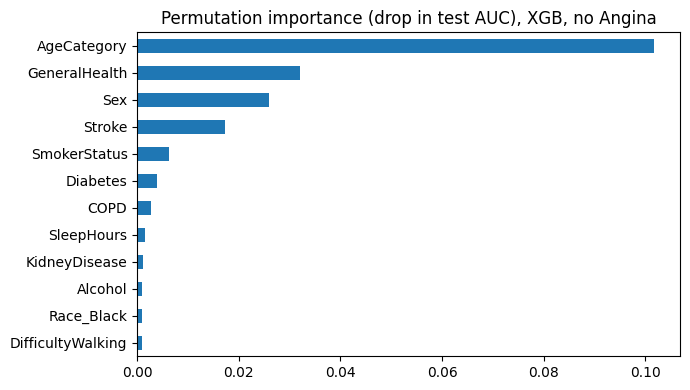

In [16]:
from sklearn.inspection import permutation_importance
cols_with = FEATURES + (['Angina'] if 'Angina' not in FEATURES else [])
Xa_tr, Xa_te = df.loc[train_idx, cols_with].reset_index(drop=True), df.loc[test_idx, cols_with].reset_index(drop=True)
abl = []
for label, cols in [('without Angina', [c for c in cols_with if c != 'Angina']), ('with Angina', cols_with)]:
    m = base_models()['XGB'].fit(Xa_tr[cols], ytr)
    abl.append({'feature set': label, 'XGB test AUC': roc_auc_score(yte, m.predict_proba(Xa_te[cols])[:, 1])})
display(pd.DataFrame(abl).round(4))

m = FITTED['XGB']
sub = np.random.default_rng(SEED).choice(len(Xte), min(20000, len(Xte)), replace=False)
imp = permutation_importance(m, Xte.iloc[sub], yte[sub], scoring='roc_auc', n_repeats=3, random_state=SEED, n_jobs=1)
(pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(12)
   .plot.barh(title='Permutation importance (drop in test AUC), XGB, no Angina', figsize=(7, 4)))
plt.tight_layout(); plt.show()

## 14. All models on the same test set: ROC and precision-recall

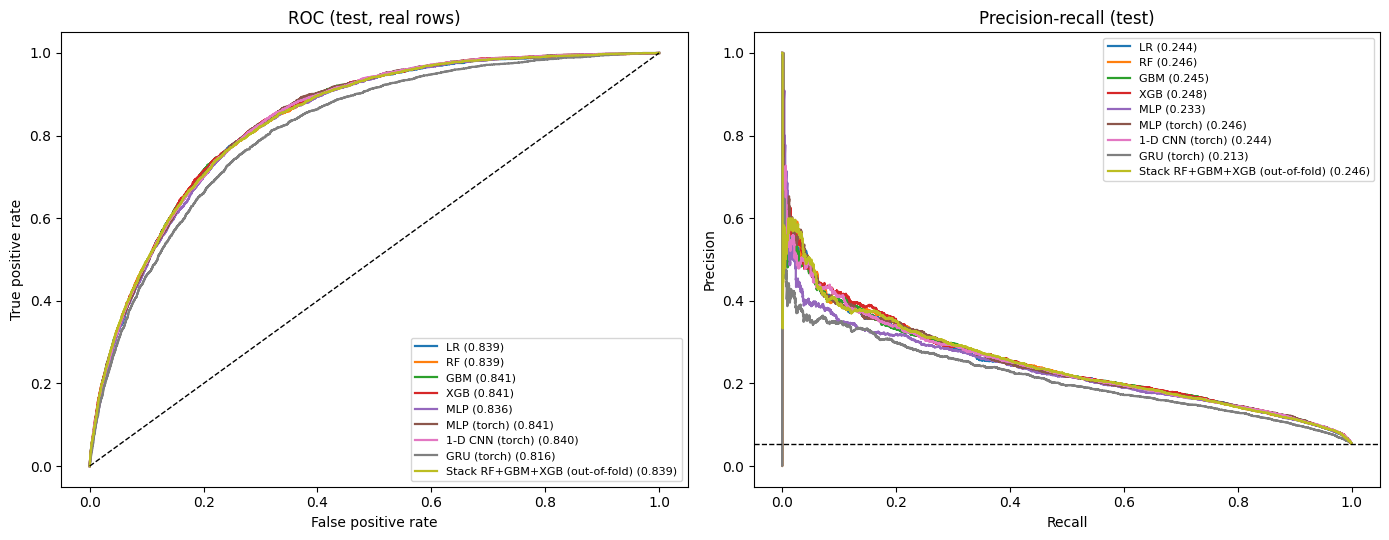

In [17]:
keep = [r['model'] for r in RESULTS if r['experiment'] in ('1 no balancing', '3 neural nets', '4 stacking')]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for k in keep:
    f, t, _ = roc_curve(yte, PROBS[k]); ax[0].plot(f, t, lw=1.6, label=f"{k} ({roc_auc_score(yte, PROBS[k]):.3f})")
    pr, rc, _ = precision_recall_curve(yte, PROBS[k]); ax[1].plot(rc, pr, lw=1.6, label=f"{k} ({average_precision_score(yte, PROBS[k]):.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].set_title('ROC (test, real rows)')
ax[1].axhline(yte.mean(), color='k', ls='--', lw=1); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision-recall (test)')
ax[0].legend(loc='lower right', fontsize=8); ax[1].legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

## 15. Final comparison table

In [18]:
final = pd.DataFrame(RESULTS)
cols = ['experiment', 'model', 'AUC', 'AUC_lo', 'AUC_hi', 'PR_AUC', 'Brier', 'calib_slope', 'obs_over_exp', 'dAUC_vs_base', 'dAUC_lo', 'dAUC_hi']
final[cols].round(4)

,experiment,model,AUC,AUC_lo,AUC_hi,PR_AUC,Brier,calib_slope,obs_over_exp,dAUC_vs_base,dAUC_lo,dAUC_hi
0,1 no balancing,LR,0.8386,0.8328,0.8457,0.2437,0.0460,1.0215,0.9988,NaN,NaN,NaN
1,1 no balancing,RF,0.8387,0.8334,0.8456,0.2455,0.0458,1.1387,0.9965,NaN,NaN,NaN
2,1 no balancing,GBM,0.8408,0.8356,0.8477,0.2447,0.0457,1.0537,0.9970,NaN,NaN,NaN
3,1 no balancing,XGB,0.8413,0.8359,0.8482,0.2484,0.0457,1.0044,1.0020,NaN,NaN,NaN
4,1 no balancing,MLP,0.8361,0.8306,0.8423,0.2327,0.0461,0.9879,0.9986,NaN,NaN,NaN
5,2 balancing,LR + class weights (raw),0.8387,0.8327,0.8459,0.2434,0.1703,0.9263,0.1551,0.0000,-0.0003,0.0004
6,2 balancing,LR + class weights (prior-corrected),0.8387,0.8327,0.8459,0.2434,0.0463,0.9260,0.9566,0.0000,-0.0003,0.0004
7,2 balancing,XGB + class weights (raw),0.8401,0.8342,0.8470,0.2475,0.1671,0.9899,0.1622,-0.0012,-0.0021,-0.0001
8,2 balancing,XGB + class weights (prior-corrected),0.8401,0.8342,0.8470,0.2475,0.0457,0.9904,1.0316,-0.0012,-0.0021,-0.0001
9,2 balancing,LR + ROS (raw),0.8386,0.8326,0.8458,0.2432,0.1704,0.9267,0.1551,-0.0001,-0.0004,0.0003


## 16. Conclusions (read together with the printed tables above)
1. **Honest discrimination** of these self-reported survey variables is about 0.84 AUC, with intervals of about +/-0.007.
   Logistic regression, random forest, gradient boosting, XGBoost and the MLP / 1-D CNN land within a few thousandths of each other
   (differences of 0.003-0.004 at most); the GRU is slightly worse. More complex models buy essentially nothing here.
2. **Balancing does not add discrimination**: class weights and random oversampling tie with no balancing; SMOTE-NC and CTGAN are
   clearly *worse* (see the dAUC columns, which are paired and carry confidence intervals). Balancing does distort raw probabilities
   (observed/expected far from 1); a prior-shift correction repairs the scale but not the ranking.
3. **Out-of-fold stacking** is no better than its best member (the interval for the difference includes zero); the 0.66-0.68 seen
   originally was an artefact of in-sample meta-features.
4. **CTGAN rows are detectable** (detectability AUC far above 0.5) and a share fall outside the observed range; they do not help
   held-out real patients and cost several points of AUC.
5. **The 0.95-0.98 results** come from synthesising before splitting (section 11), not from the models.
6. **`Angina` is a sibling outcome.** It raises AUC substantially (section 13), but it is not a risk factor, so the main analysis excludes it.
7. **Scope:** this is prevalent self-reported disease in a cross-sectional survey, a screening-style association model. It is not a
   10-year risk model; prediction of future events needs longitudinal data with follow-up and, ideally, clinical measurements.